# FGSM across frameworks: local `fgsm` vs ART `art_fgsm`

We attack one comma10k frame with the Fast Gradient Sign Method, against six target models: a detector and a classifier per framework, except JAX (no pretrained Flax detector is available off the shelf).

| § | Task | Target model | Framework | Adapter (`examples/adapters/`) |
|---|---|---|---|---|
| 1–2 | Detection | YOLOv8n (COCO) | PyTorch | `torch_detector_target.py` (any ultralytics detector) |
| 3 | Detection | D-FINE nano (COCO) | TensorFlow / Keras | `keras_detector_target.py` (KerasHub D-FINE or RetinaNet) |
| 4 | Classification | ResNet-50 (ImageNet) | PyTorch | `torch_classifier_target.py` (any `torchvision.models` classifier) |
| 5 | Classification | MobileNetV2 (ImageNet) | TensorFlow / Keras | `keras_classifier_target.py` (any `keras.applications` classifier) |
| 6 | Classification | ViT-B/16 (ImageNet) | JAX / Flax | `flax_classifier_target.py` (any Hugging Face Flax classifier) |

kcai only asks a target model for two things: a `name`, and `grad(x)`, the gradient of a loss with respect to an image in `[0, 1]`. Each adapter implements `grad` with its framework's autograd. Two transformations then use that gradient:

- **`fgsm`** (`kcai-data-sampling-fgsm`): kcai's own implementation, `x + ε·sign(grad)`.
- **`art_fgsm`** (`kcai-data-sampling-art`): ART's `FastGradientMethod`.

On every model, both must produce **the same image**.

**Environment**: the `kcai` env with `kcai-data-sampling[job,images,fgsm]`, the `-art` package (`pip install -e packages/kcai-data-sampling-art`), `ultralytics` and `torchvision`. The TensorFlow sections need `tensorflow-cpu`, and §3 also `keras-hub` (`pip install --no-deps keras-hub kagglehub kagglesdk`: its full `tensorflow` dependency would clash with `tensorflow-cpu`). §6 needs `jax flax "transformers<5"`. You also need `yolov8n.pt` at the repository root and the comma10k sample from `scripts/fetch_comma10k_sample.py`.

## Setup

Import `torch` **before** `tensorflow`: the reverse order crashes Python with tensorflow-cpu 2.21 and torchvision 0.29.

In [1]:
import os
import sys
from pathlib import Path

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"  # hide TensorFlow's C++ logs
import torch  # noqa: F401  (before tensorflow, see above)
import torchvision  # noqa: F401

import numpy as np
from PIL import Image

# Work from the repository root, and make the adapters and display helpers importable.
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / ".git").exists())
os.chdir(REPO)
sys.path[:0] = ["examples/adapters", "examples/notebooks"]

from display import show
from kcai_data_sampling_fgsm.api.transformations.fgsm import Fgsm
from kcai_data_sampling_art.api.transformations.fgsm import ArtFgsm

/home/lucasschott/miniforge3/envs/kcai/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Transformations work on batches. Here `x` is a batch of one RGBA `uint8` image, shape `(1, H, W, 4)`, as the kcai dataloader produces it.

`EPSILON` is the attack budget in `[0, 1]` units: 8/255 lets each pixel move by at most 8 grey levels.

(1, 1208, 1928, 4) uint8



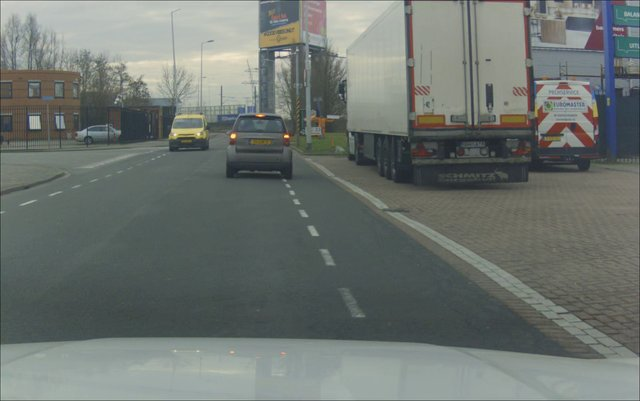

In [2]:
image_path = sorted(Path("examples/data/comma10k_sample/imgs").glob("*.png"))[0]
x = np.asarray(Image.open(image_path).convert("RGBA"))[None]
EPSILON = 8 / 255

print(x.shape, x.dtype)
show([("original", x[0])])

The perturbation is invisible at 8 grey levels, so this helper stretches it for display (grey = unchanged).

In [3]:
def perturbation(x_adv):
    delta = x_adv[0, ..., :3].astype(int) - x[0, ..., :3]
    return np.clip(128 + delta * 16, 0, 255).astype(np.uint8)

## 1. PyTorch detector: YOLOv8n, local `fgsm`

`TorchDetectorTarget.grad` backpropagates minus the total confidence of the detections YOLO reports (scores above 0.25). Increasing that loss lowers the confidence, so the attack tries to make objects disappear.


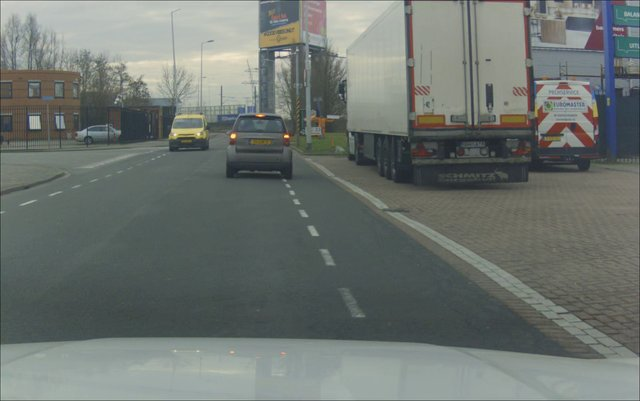
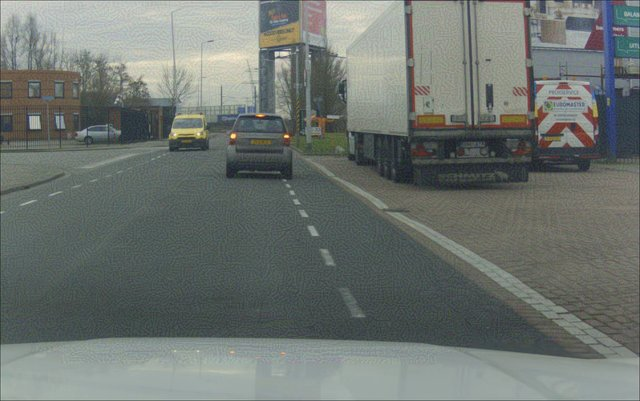
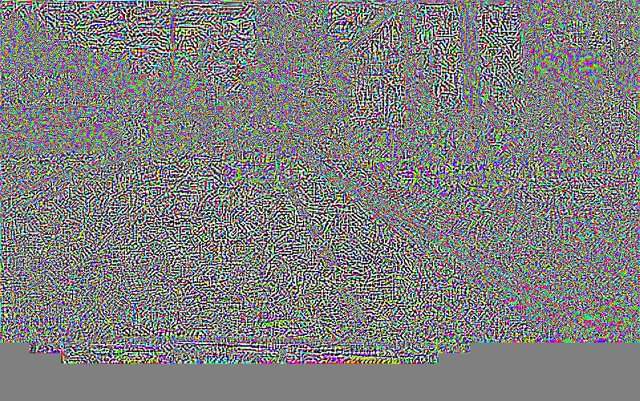

In [4]:
from torch_detector_target import TorchDetectorTarget

yolo = TorchDetectorTarget(weights="yolov8n.pt")

fgsm = Fgsm({"target_model": yolo, "epsilon": EPSILON})
x_adv = fgsm.apply(x)

show([("original", x[0]), ("fgsm", x_adv[0]), ("perturbation (x16)", perturbation(x_adv))])

## 2. PyTorch detector: same YOLOv8n, ART `art_fgsm`

The same target model goes to ART. It should give exactly the image from §1.

In [5]:
art_fgsm = ArtFgsm({"target_model": yolo, "epsilon": EPSILON})
x_adv_art = art_fgsm.apply(x)

print("same image as fgsm:", np.array_equal(x_adv, x_adv_art))

same image as fgsm: True


Does it fool the detector? We run YOLO on the original and attacked images.


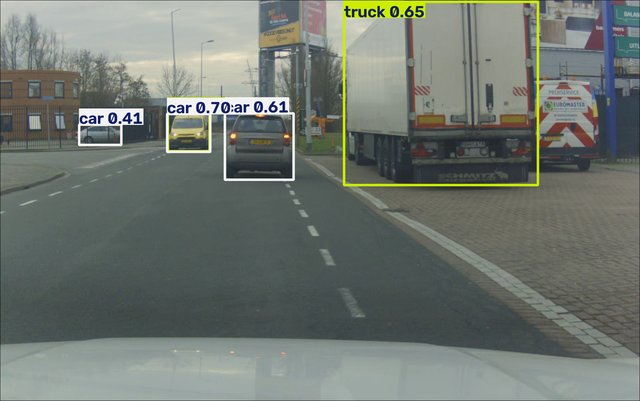
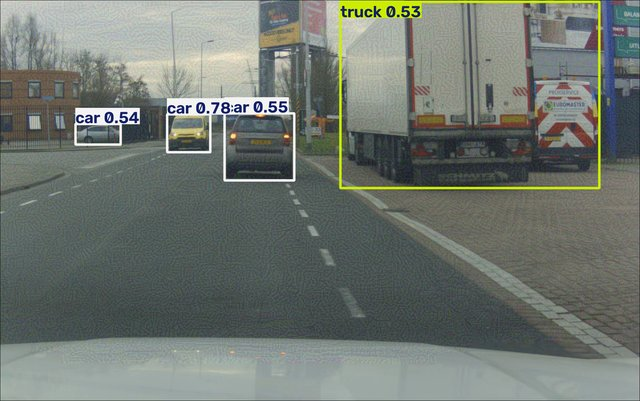

In [6]:
from ultralytics import YOLO

detector = YOLO("yolov8n.pt")


def detect(batch):
    result = detector.predict(Image.fromarray(batch[0, ..., :3]), conf=0.25, verbose=False)[0]
    return len(result.boxes), result.plot()[..., ::-1]  # plot() draws in BGR


n_before, boxes_before = detect(x)
n_after, boxes_after = detect(x_adv_art)
show([(f"original: {n_before} detections", boxes_before), (f"art_fgsm: {n_after} detections", boxes_after)])

One FGSM step of 8 grey levels lowers the detector's confidence but removes only a little. Single-step FGSM is the weakest gradient attack; iterative ones (PGD) take many such steps.

## 3. TensorFlow detector: KerasHub D-FINE

`KerasDetectorTarget` works with KerasHub's COCO detectors, chosen by preset name; here the smallest D-FINE. As for YOLO, the detector's own `predict` ends with non-maximum suppression, which has no gradient, so `grad` reads the network's raw class scores and backpropagates minus the total confidence of the detections above 0.5, with `tf.GradientTape`.

In [7]:
from keras_detector_target import KerasDetectorTarget

dfine = KerasDetectorTarget(weights="dfine_nano_coco")  # KerasHub downloads the weights on first use

x_adv = Fgsm({"target_model": dfine, "epsilon": EPSILON}).apply(x)
x_adv_art = ArtFgsm({"target_model": dfine, "epsilon": EPSILON}).apply(x)

print("same image as fgsm:", np.array_equal(x_adv, x_adv_art))

I0000 00:00:1792232721.147108   31939 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1792232728.586250   31939 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


same image as fgsm: True


Does it fool the detector? The adapter sees the whole frame resized to 640×640, so we detect on that same view and draw the boxes back on the full image. D-FINE uses the COCO classes in the same order as YOLO.


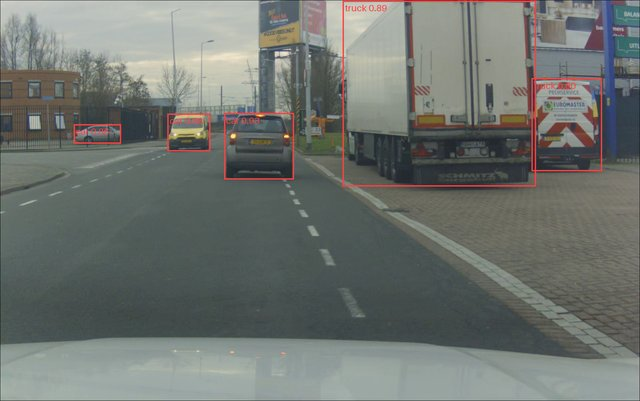
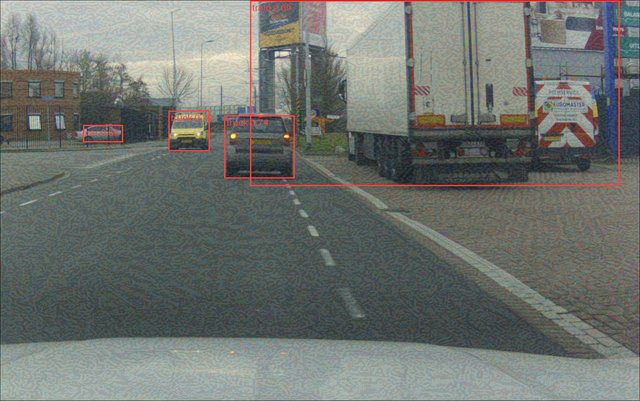

In [8]:
from PIL import ImageDraw


def detect_dfine(batch):
    height, width = batch.shape[1:3]
    resized = dfine.tf.image.resize(batch[..., :3].astype(np.float32), dfine.input_size, antialias=True)
    found = dfine.model.predict(resized, verbose=0)  # decoding + non-maximum suppression
    n = int(found["num_detections"][0])
    image = Image.fromarray(batch[0, ..., :3])
    draw = ImageDraw.Draw(image)
    sy, sx = height / dfine.input_size[0], width / dfine.input_size[1]
    for (y0, x0, y1, x1), label, score in zip(found["boxes"][0][:n], found["labels"][0][:n], found["confidence"][0][:n]):
        draw.rectangle([x0 * sx, y0 * sy, x1 * sx, y1 * sy], outline=(255, 64, 64), width=4)
        draw.text((x0 * sx + 6, y0 * sy + 4), f"{detector.names[int(label)]} {score:.2f}", fill=(255, 64, 64), font_size=28)
    return n, np.asarray(image)


n_before, boxes_before = detect_dfine(x)
n_after, boxes_after = detect_dfine(x_adv_art)
show([(f"original: {n_before} detections", boxes_before), (f"art_fgsm: {n_after} detections", boxes_after)])

## 4. PyTorch classifier: torchvision ResNet-50

`TorchClassifierTarget` works with any classifier in `torchvision.models`, chosen by name. It reads the input size and normalization from the weights' own preprocessing. `grad` uses `torch.autograd`. The loss is the cross-entropy of the model's own top-1 class, so the attack pushes the model away from what it currently sees, without needing a ground-truth label. The classifiers in §5–6 use the same loss.

In [9]:
from torch_classifier_target import TorchClassifierTarget

resnet = TorchClassifierTarget(model="resnet50")  # torchvision downloads the weights on first use

x_adv = Fgsm({"target_model": resnet, "epsilon": EPSILON}).apply(x)
x_adv_art = ArtFgsm({"target_model": resnet, "epsilon": EPSILON}).apply(x)

print("same image as fgsm:", np.array_equal(x_adv, x_adv_art))

same image as fgsm: True


Does it fool the classifier? We compare its top 3 classes before and after, using `predict` (class probabilities) and the ImageNet class names. All the classifiers in this notebook use the standard ImageNet class order.

original: trailer truck 21%, traffic light 5%, garbage truck 4%


art_fgsm: streetcar 17%, bookshop 4%, trolleybus 4%
pixels changed: 100%



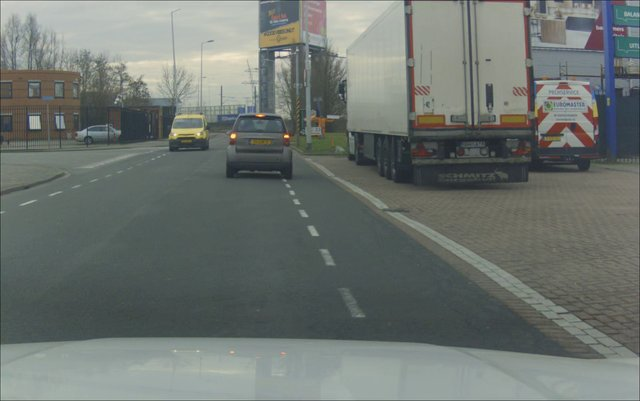
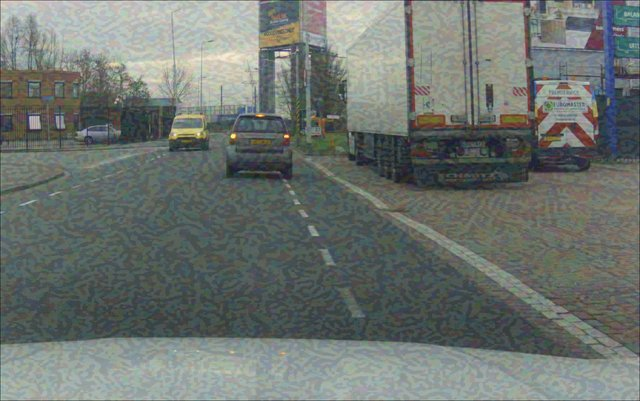
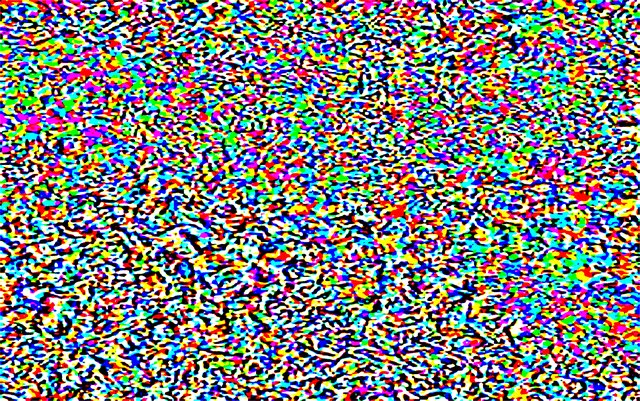

In [10]:
from transformers import AutoConfig

IMAGENET = AutoConfig.from_pretrained("google/vit-base-patch16-224").id2label  # class index -> name


def top3(classifier, batch):
    probs = classifier.predict(batch / 255)[0]
    return ", ".join(f"{IMAGENET[i].split(',')[0]} {probs[i]:.0%}" for i in np.argsort(probs)[::-1][:3])


print("original:", top3(resnet, x))
print("art_fgsm:", top3(resnet, x_adv_art))
print(f"pixels changed: {(x_adv_art != x).any(axis=-1).mean():.0%}")
show([("original", x[0]), ("art_fgsm", x_adv_art[0]), ("perturbation (x16)", perturbation(x_adv_art))])

Every pixel changes because the adapter resizes with `antialias=True`. A plain bilinear resize from 1928 to 224 pixels would read only a few source pixels: all the others would get a zero gradient, and FGSM would leave them as they are (`sign(0) = 0`).

## 5. TensorFlow classifier: Keras MobileNetV2

`KerasClassifierTarget` works with any classifier in `keras.applications`, chosen by name. It reads the input size from the model and uses Keras's own preprocessing for it. `grad` uses `tf.GradientTape` on the same loss as §4.

same image as fgsm: True


original: trailer truck 32%, moving van 18%, garbage truck 6%


art_fgsm: quilt 30%, streetcar 27%, prayer rug 2%
pixels changed: 100%



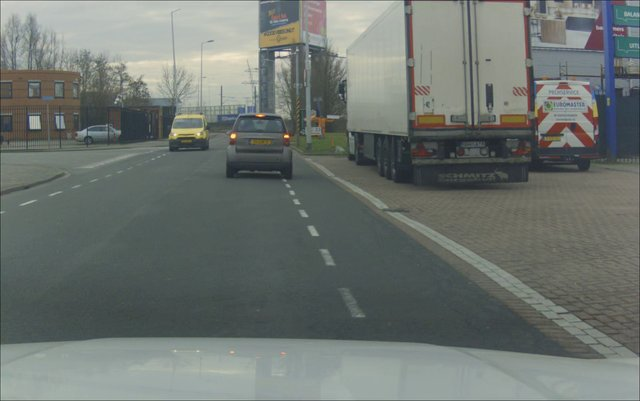
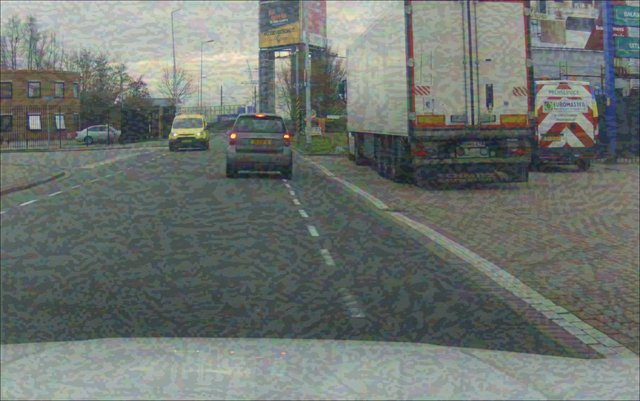
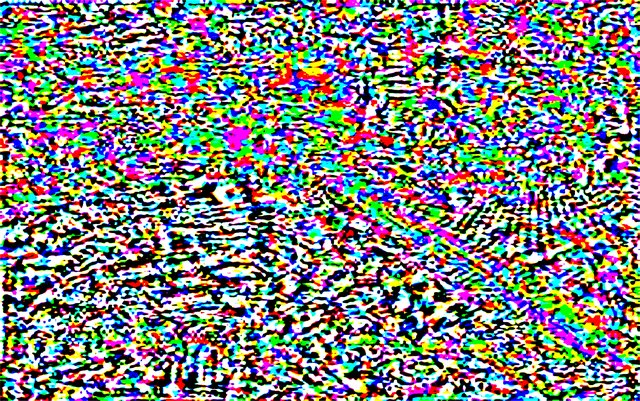

In [11]:
from keras_classifier_target import KerasClassifierTarget

mobilenet = KerasClassifierTarget(model="MobileNetV2")  # Keras downloads the weights on first use

x_adv = Fgsm({"target_model": mobilenet, "epsilon": EPSILON}).apply(x)
x_adv_art = ArtFgsm({"target_model": mobilenet, "epsilon": EPSILON}).apply(x)

print("same image as fgsm:", np.array_equal(x_adv, x_adv_art))
print("original:", top3(mobilenet, x))
print("art_fgsm:", top3(mobilenet, x_adv_art))
print(f"pixels changed: {(x_adv_art != x).any(axis=-1).mean():.0%}")
show([("original", x[0]), ("art_fgsm", x_adv_art[0]), ("perturbation (x16)", perturbation(x_adv_art))])

## 6. JAX classifier: Flax ViT-B/16

`FlaxClassifierTarget` works with any Hugging Face image classifier that has Flax weights, chosen by model id; it reads the input size and normalization from the model's image processor. `grad` is `jax.grad` of the same loss as §4–5, here on Google's `google/vit-base-patch16-224`. No PyTorch or TensorFlow is involved.

TensorFlow and JAX classes are deprecated and will be removed in Transformers v5. We recommend migrating to PyTorch classes or pinning your version of Transformers.


An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.


Fast image processor class <class 'transformers.models.vit.image_processing_vit_fast.ViTImageProcessorFast'> is available for this model. Using slow image processor class. To use the fast image processor class set `use_fast=True`.


same image as fgsm: True


original: trailer truck 55%, moving van 31%, minibus 2%


art_fgsm: streetcar 48%, passenger car 21%, trolleybus 17%
pixels changed: 100%



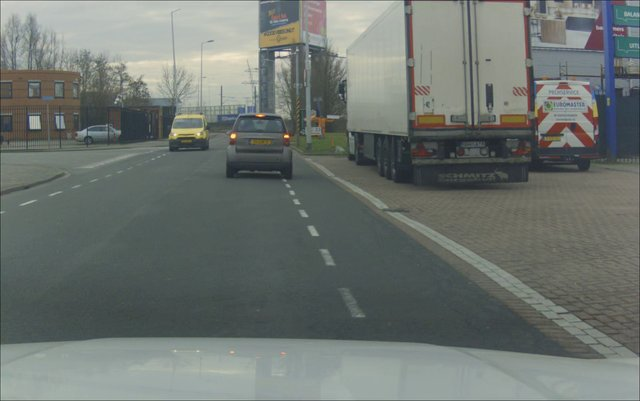
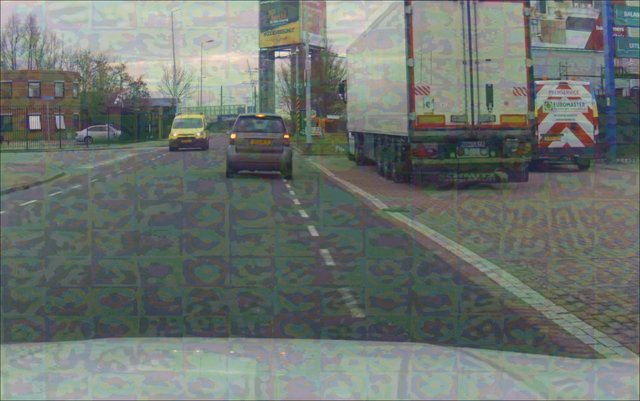
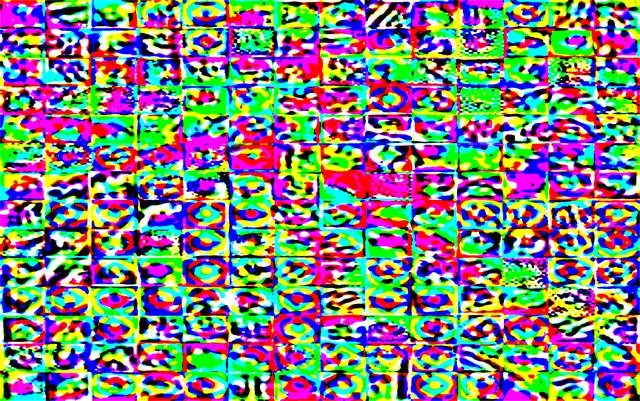

In [12]:
from flax_classifier_target import FlaxClassifierTarget

vit = FlaxClassifierTarget(weights="google/vit-base-patch16-224")  # Hugging Face downloads the weights on first use

x_adv = Fgsm({"target_model": vit, "epsilon": EPSILON}).apply(x)
x_adv_art = ArtFgsm({"target_model": vit, "epsilon": EPSILON}).apply(x)

print("same image as fgsm:", np.array_equal(x_adv, x_adv_art))
print("original:", top3(vit, x))
print("art_fgsm:", top3(vit, x_adv_art))
print(f"pixels changed: {(x_adv_art != x).any(axis=-1).mean():.0%}")
show([("original", x[0]), ("art_fgsm", x_adv_art[0]), ("perturbation (x16)", perturbation(x_adv_art))])

## Takeaways

- **`fgsm` and `art_fgsm` give the same image** on all six models, in PyTorch, TensorFlow and JAX. For FGSM, ART adds nothing; its value comes with the next attacks (PGD, C&W, …).
- **Supporting a framework or a task means writing one adapter.** The transformations and ART are unchanged; only the adapter's `grad` uses the framework's autograd and the task's loss.
- **The attack is only as good as the adapter's loss.** The detection loss lowers the detectors' confidence but removes few boxes in one step; the cross-entropy loss changes every classifier's top-1 class at 8 grey levels.
- **The adapter's preprocessing matters too.** It must stay inside the gradient computation, and resize with antialiasing so that every pixel can be attacked. Detectors' `predict` (decoding + non-maximum suppression) has no gradient: the adapter reads the raw scores instead.